<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/solitons/soliton_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*TASI Lectures on Solitons* — `soliton_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Solitons Ch 2 · Monopoles — Figure Notebook
Based on D. Tong, TASI Lectures on Solitons

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
AMB  = '#e8a838'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; BLUE = '#89c4f4'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

CH = 'ch02'
os.makedirs(f'figures/{CH}', exist_ok=True)

def save(name, fig):
    fig.savefig(f'figures/{CH}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: figures/{CH}/{name}')

print('Setup complete.')


Setup complete.


## Fig 01 · 't Hooft–Polyakov Monopole Profile

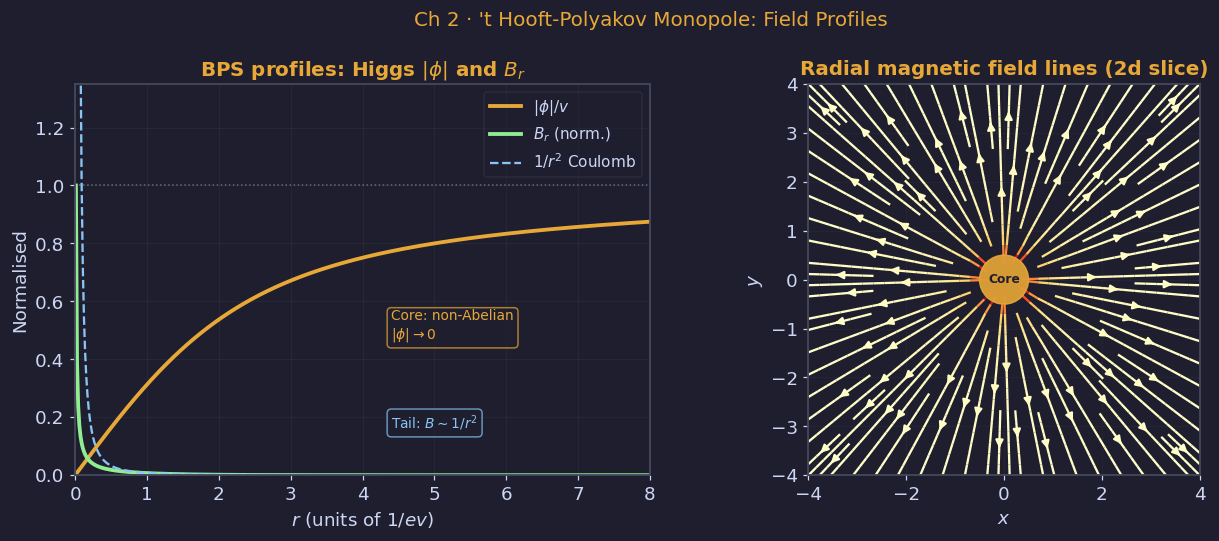

Saved: figures/ch02/fig01_monopole_profile.png


In [2]:
# ── fig01: 't Hooft-Polyakov monopole profiles ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 2 · 't Hooft-Polyakov Monopole: Field Profiles", color=AMB, fontsize=13)

r = np.linspace(0.01, 8.0, 500); v = 1.0
phi = v*(1.0/np.tanh(v*r) - 1.0/(v*r))
B_r = v**2*r/np.sinh(v*r)**2
B_asym = 1.0/r**2

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS profiles: Higgs $|\phi|$ and $B_r$", color=AMB)
ax.plot(r, phi/v,           color=AMB,   lw=2.5, label=r'$|\phi|/v$')
ax.plot(r, B_r/B_r.max(),   color=GREEN, lw=2.5, label=r'$B_r$ (norm.)')
ax.plot(r, np.minimum(B_asym/B_asym[5], 1.5), color=BLUE, lw=1.5,
        ls='--', label=r'$1/r^2$ Coulomb')
ax.axhline(1.0, color=FG, ls=':', lw=1, alpha=0.4)
ax.set_xlabel(r'$r$ (units of $1/ev$)'); ax.set_ylabel('Normalised')
ax.set_ylim(0, 1.35); ax.set_xlim(0, 8)
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
ax.text(0.55, 0.35, "Core: non-Abelian\n" + r"$|\phi|\to 0$", transform=ax.transAxes,
        fontsize=9, color=AMB, bbox=dict(boxstyle='round', fc=BG, ec=AMB, alpha=0.7))
ax.text(0.55, 0.12, r"Tail: $B\sim 1/r^2$", transform=ax.transAxes,
        fontsize=9, color=BLUE, bbox=dict(boxstyle='round', fc=BG, ec=BLUE, alpha=0.7))

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"Radial magnetic field lines (2d slice)", color=AMB)
x2 = np.linspace(-4, 4, 20); y2 = np.linspace(-4, 4, 20)
Xg, Yg = np.meshgrid(x2, y2)
R2 = np.sqrt(Xg**2 + Yg**2) + 0.1
Bx = Xg/R2**3; By = Yg/R2**3
ax2.streamplot(x2, y2, Bx, By, color=np.sqrt(Bx**2+By**2),
               cmap='YlOrRd', linewidth=1.5, density=1.2)
ax2.add_patch(plt.Circle((0,0), 0.5, color=AMB, zorder=5, alpha=0.9))
ax2.text(0, 0, 'Core', ha='center', va='center', fontsize=8,
         color=BG, fontweight='bold', zorder=6)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$')
ax2.set_xlim(-4,4); ax2.set_ylim(-4,4); ax2.set_aspect('equal')
ax2.grid(True, alpha=0.15)
plt.tight_layout()
save('fig01_monopole_profile.png', fig)


## Fig 02 · Two-Monopole 90° Scattering

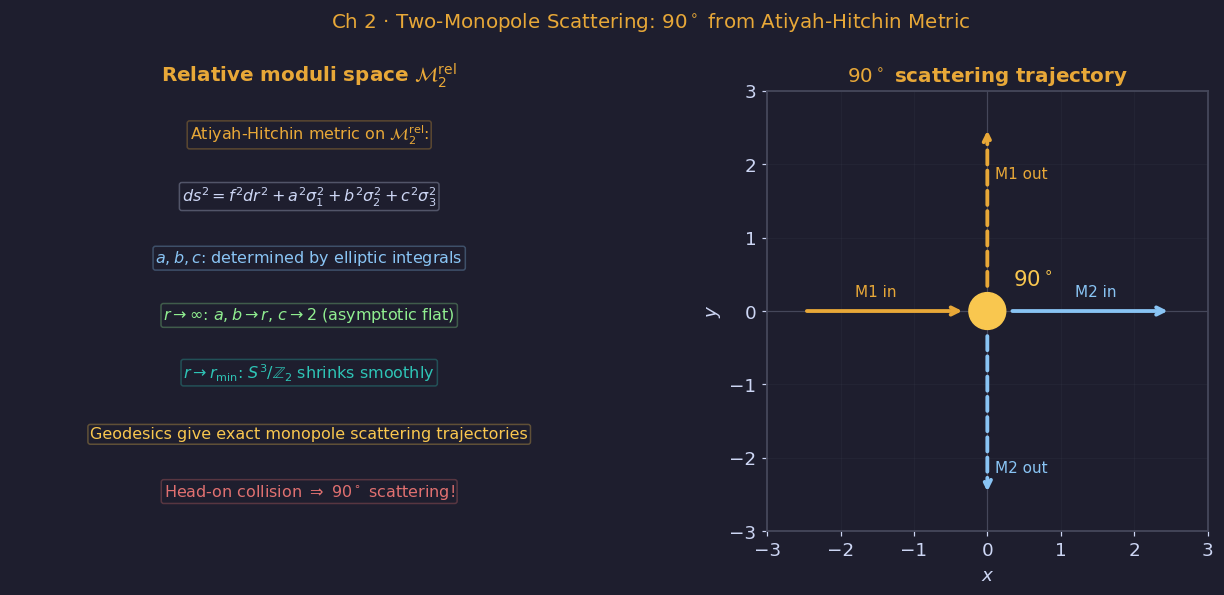

Saved: figures/ch02/fig02_atiyah_hitchin.png


In [3]:
# ── fig02: two-monopole 90-degree scattering ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r"Ch 2 · Two-Monopole Scattering: 90$^\circ$ from Atiyah-Hitchin Metric",
             color=AMB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"Relative moduli space $\mathcal{M}_2^{\rm rel}$", color=AMB)
items = [
    (0.50, 0.90, r"Atiyah-Hitchin metric on $\mathcal{M}_2^{\rm rel}$:", AMB),
    (0.50, 0.76, r"$ds^2=f^2dr^2+a^2\sigma_1^2+b^2\sigma_2^2+c^2\sigma_3^2$", FG),
    (0.50, 0.62, r"$a,b,c$: determined by elliptic integrals", BLUE),
    (0.50, 0.49, r"$r\to\infty$: $a,b\to r$, $c\to 2$ (asymptotic flat)", GREEN),
    (0.50, 0.36, r"$r\to r_{\rm min}$: $S^3/\mathbb{Z}_2$ shrinks smoothly", TEAL),
    (0.50, 0.22, r"Geodesics give exact monopole scattering trajectories", YELL),
    (0.50, 0.09, r"Head-on collision $\Rightarrow$ $90^\circ$ scattering!", RED),
]
for (x, y, txt, col) in items:
    ax.text(x, y, txt, ha='center', va='center', fontsize=10.5,
            color=col, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"$90^\circ$ scattering trajectory", color=AMB)
t = np.linspace(0, 1, 200)
# Approach along x, exit along y
ax2.annotate('', xy=(-0.3, 0), xytext=(-2.5, 0),
             arrowprops=dict(arrowstyle='->', color=AMB, lw=2.5))
ax2.annotate('', xy=(2.5, 0), xytext=(0.3, 0),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax2.annotate('', xy=(0, 2.5), xytext=(0, 0.3),
             arrowprops=dict(arrowstyle='->', color=AMB, lw=2.5, linestyle='dashed'))
ax2.annotate('', xy=(0, -2.5), xytext=(0, -0.3),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, linestyle='dashed'))

ax2.text(-1.8,  0.2, "M1 in",  color=AMB,  fontsize=10)
ax2.text( 1.2,  0.2, "M2 in",  color=BLUE, fontsize=10)
ax2.text( 0.1,  1.8, "M1 out", color=AMB,  fontsize=10)
ax2.text( 0.1, -2.2, "M2 out", color=BLUE, fontsize=10)

ax2.add_patch(plt.Circle((0,0), 0.25, color=YELL, zorder=5))
ax2.text(0.35, 0.35, r"$90^\circ$", fontsize=14, color=YELL)
ax2.set_xlim(-3, 3); ax2.set_ylim(-3, 3); ax2.set_aspect('equal')
ax2.axhline(0, color=EDGE, lw=0.8); ax2.axvline(0, color=EDGE, lw=0.8)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$')
ax2.grid(True, alpha=0.15)
plt.tight_layout()
save('fig02_atiyah_hitchin.png', fig)


## Fig 03 · Nahm Construction

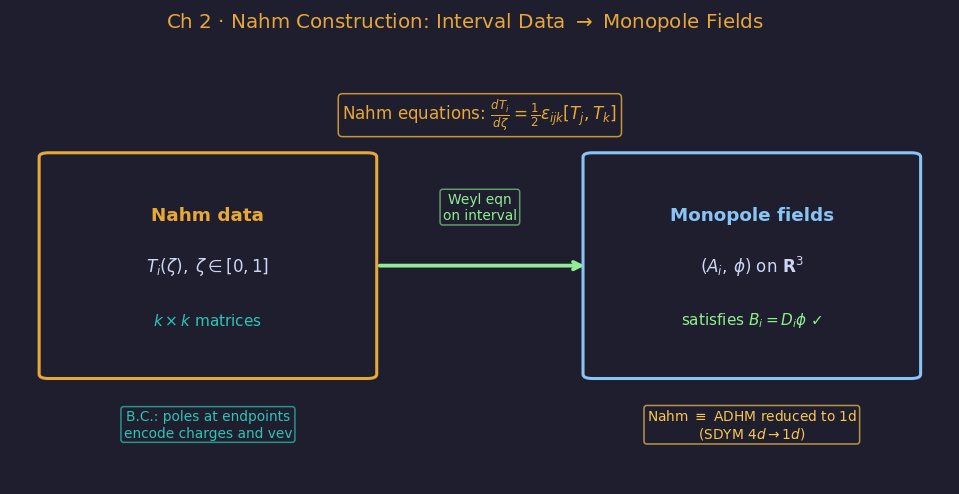

Saved: figures/ch02/fig03_nahm_construction.png


In [4]:
# ── fig03: Nahm construction schematic (revised) ─────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle(r"Ch 2 · Nahm Construction: Interval Data $\to$ Monopole Fields",
             color=AMB, fontsize=13)
ax.set_facecolor(BG); ax.axis('off')

# ── 박스 경계 좌표 (axes fraction) ──────────────────────────────────────
# 왼쪽 박스: x [0.04, 0.38],  y [0.26, 0.78]
# 오른쪽 박스: x [0.62, 0.96], y [0.26, 0.78]
# 화살표: x 0.38 → 0.62 (박스 바깥 경계 정확히 연결)

LX0, LX1 = 0.04, 0.38   # Left box x range
RX0, RX1 = 0.62, 0.96   # Right box x range
BY0, BY1 = 0.26, 0.78   # Both boxes y range
MID_Y    = (BY0 + BY1) / 2   # 0.52

# ── Left box: Nahm data ──────────────────────────────────────────────────
rect1 = FancyBboxPatch((LX0, BY0), LX1-LX0, BY1-BY0,
                        boxstyle="round,pad=0.01", lw=2,
                        edgecolor=AMB, facecolor=BG, transform=ax.transAxes)
ax.add_patch(rect1)
ax.text((LX0+LX1)/2, MID_Y+0.12, "Nahm data",
        ha='center', va='center', fontsize=12, fontweight='bold',
        color=AMB, transform=ax.transAxes)
ax.text((LX0+LX1)/2, MID_Y,      r"$T_i(\zeta),\;\zeta\in[0,1]$",
        ha='center', va='center', fontsize=11, color=FG, transform=ax.transAxes)
ax.text((LX0+LX1)/2, MID_Y-0.13, r"$k\times k$ matrices",
        ha='center', va='center', fontsize=10, color=TEAL, transform=ax.transAxes)

# ── Right box: Monopole fields ───────────────────────────────────────────
rect2 = FancyBboxPatch((RX0, BY0), RX1-RX0, BY1-BY0,
                        boxstyle="round,pad=0.01", lw=2,
                        edgecolor=BLUE, facecolor=BG, transform=ax.transAxes)
ax.add_patch(rect2)
ax.text((RX0+RX1)/2, MID_Y+0.12, "Monopole fields",
        ha='center', va='center', fontsize=12, fontweight='bold',
        color=BLUE, transform=ax.transAxes)
ax.text((RX0+RX1)/2, MID_Y,      r"$(A_i,\,\phi)$ on $\mathbf{R}^3$",
        ha='center', va='center', fontsize=11, color=FG, transform=ax.transAxes)
ax.text((RX0+RX1)/2, MID_Y-0.13, r"satisfies $B_i=D_i\phi\;\checkmark$",
        ha='center', va='center', fontsize=10, color=GREEN, transform=ax.transAxes)

# ── Arrow: 박스 오른쪽 경계 → 왼쪽 경계 (박스 밖만 연결) ────────────────
ax.annotate('', xy=(RX0-0.005, MID_Y), xytext=(LX1+0.01, MID_Y),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5))

# ── "Weyl eqn" label: 화살표 중앙 위 ────────────────────────────────────
ARR_MID_X = (LX1 + RX0) / 2   # 0.50
ax.text(ARR_MID_X, MID_Y + 0.14, "Weyl eqn\non interval",
        ha='center', va='center', fontsize=9, color=GREEN,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, alpha=0.6))

# ── Nahm equations box: 화살표 정중앙 위 (겹침 없이) ─────────────────────
ax.text(ARR_MID_X, BY1 + 0.10,
        r"Nahm equations: $\frac{dT_i}{d\zeta}=\frac{1}{2}\epsilon_{ijk}[T_j,T_k]$",
        ha='center', va='center', fontsize=11, color=AMB,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=AMB, alpha=0.85))

# ── Bottom notes: 각 박스 바로 아래 ─────────────────────────────────────
ax.text((LX0+LX1)/2, BY0 - 0.12,
        "B.C.: poles at endpoints\nencode charges and vev",
        ha='center', va='center', fontsize=9, color=TEAL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=TEAL, alpha=0.7))

ax.text((RX0+RX1)/2, BY0 - 0.12,
        r"Nahm $\equiv$ ADHM reduced to 1d" + "\n" + r"(SDYM $4d\to 1d$)",
        ha='center', va='center', fontsize=9, color=YELL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=YELL, alpha=0.7))

fig.subplots_adjust(top=0.88, bottom=0.12)
save('fig03_nahm_construction.png', fig)

## Fig 04 · S-Duality Dyon Lattice

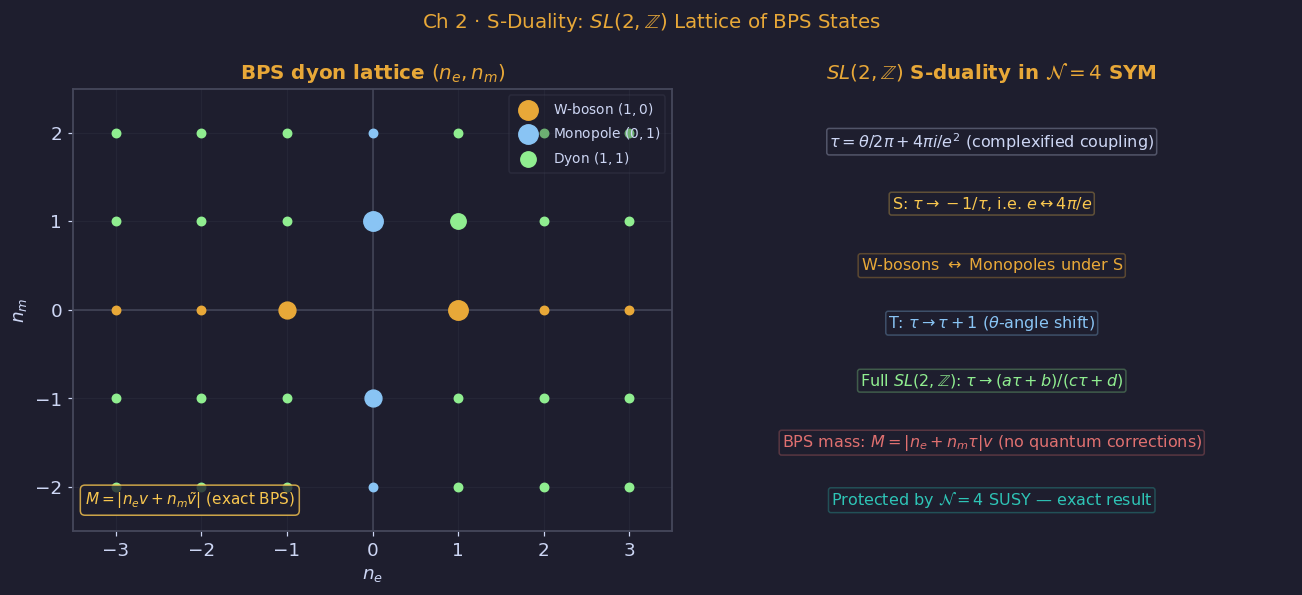

Saved: figures/ch02/fig04_sduality_lattice.png


In [5]:
# ── fig04: S-duality BPS dyon lattice ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r"Ch 2 · S-Duality: $SL(2,\mathbb{Z})$ Lattice of BPS States",
             color=AMB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS dyon lattice $(n_e, n_m)$", color=AMB)
for ne in range(-3, 4):
    for nm in range(-2, 3):
        if ne == 0 and nm == 0: continue
        col = AMB if nm==0 else (BLUE if ne==0 else GREEN)
        s   = 120 if (abs(ne)+abs(nm)==1) else 30
        ax.scatter(ne, nm, color=col, s=s, zorder=3)
ax.scatter(1,  0, color=AMB,   s=160, zorder=4, label=r'W-boson $(1,0)$')
ax.scatter(0,  1, color=BLUE,  s=160, zorder=4, label=r'Monopole $(0,1)$')
ax.scatter(1,  1, color=GREEN, s=100, zorder=4, label=r'Dyon $(1,1)$')
ax.axhline(0, color=EDGE, lw=1); ax.axvline(0, color=EDGE, lw=1)
ax.set_xlabel(r'$n_e$'); ax.set_ylabel(r'$n_m$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)
ax.set_xlim(-3.5,3.5); ax.set_ylim(-2.5,2.5)
ax.text(0.02, 0.06, r'$M=|n_e v+n_m\tilde v|$ (exact BPS)',
        transform=ax.transAxes, fontsize=10, color=YELL,
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.8))

ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r"$SL(2,\mathbb{Z})$ S-duality in $\mathcal{N}=4$ SYM", color=AMB)
items = [
    (0.50, 0.88, r'$\tau=\theta/2\pi+4\pi i/e^2$ (complexified coupling)', FG),
    (0.50, 0.74, r'S: $\tau\to-1/\tau$, i.e. $e\leftrightarrow 4\pi/e$', YELL),
    (0.50, 0.60, r'W-bosons $\leftrightarrow$ Monopoles under S', AMB),
    (0.50, 0.47, r'T: $\tau\to\tau+1$ ($\theta$-angle shift)', BLUE),
    (0.50, 0.34, r'Full $SL(2,\mathbb{Z})$: $\tau\to(a\tau+b)/(c\tau+d)$', GREEN),
    (0.50, 0.20, r'BPS mass: $M=|n_e+n_m\tau|v$ (no quantum corrections)', RED),
    (0.50, 0.07, r'Protected by $\mathcal{N}=4$ SUSY — exact result', TEAL),
]
for (x, y, txt, col) in items:
    ax2.text(x, y, txt, ha='center', va='center', fontsize=10.5,
             color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))
plt.tight_layout()
save('fig04_sduality_lattice.png', fig)


## Download

In [6]:
# ── Download figures as zip ─────────────────────────────────────────────
import shutil
CH = 'ch02'
shutil.make_archive(f'{CH}_figures', 'zip', f'figures/{CH}')
try:
    from google.colab import files
    files.download(f'{CH}_figures.zip')
except ImportError:
    print(f'Not in Colab — saved to figures/{CH}/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>